> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 🛒 Lesson 5: Association Rule Learning
### *"Farmers who buy DAP fertiliser also buy hybrid seed… or do they?"*

**Week 10 · Session 5 of 6 · ⏱ about 2 hours**

---

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Describe **transactions, items, and itemsets**.
2. Compute and interpret **support, confidence, and lift** (and know why confidence alone is dangerous).
3. Explain the **Apriori principle** and why it makes mining feasible.
4. Implement **Apriori from scratch**, then use `mlxtend`.
5. **Filter, rank, and interpret** hundreds of rules to find the ones that matter.
6. Turn rules into **decisions**: shelf layout, bundles, recommendations.

### 📋 Prerequisites
Basic probability ideas (proportions; "probability of A given B"). pandas `groupby`. Nothing from the earlier lessons is required: association rules are a separate branch of unsupervised learning!

### 🔙 A change of scene
So far, data was a **table of numbers** and we asked *"which rows are similar?"* Now the data is **baskets**: variable-length lists of items, and we ask *"which items tend to occur together?"* There are no distances, no clusters, no labels. Just **co-occurrence**.

## 1 · The story: the agro-dealer's shelf 🧑🏽‍🌾

Mama Wanjiru runs an agro-dealer shop in Nakuru. At the end of every day she has a pile of receipts:

```
Receipt 1:  DAP fertiliser, hybrid maize seed, CAN fertiliser
Receipt 2:  Pesticide, knapsack sprayer
Receipt 3:  DAP fertiliser, hybrid maize seed
...
```

She wonders:
- *"Which products should I put side by side?"*
- *"If a farmer buys pesticide, what else should my assistant suggest?"*
- *"Which two products could I bundle for a discount?"*

**Association rule learning** mines the receipts for rules of the form:

$$ \{\text{DAP fertiliser}\} \;\Longrightarrow\; \{\text{hybrid maize seed}\} $$

read as *"transactions containing DAP tend to also contain hybrid maize seed."*

> 📖 **A famous (and probably embellished) legend:** a supermarket found that men buying nappies on Friday evenings also bought beer. True or not, it illustrates the point: *data can reveal combinations nobody thought to look for.* The technique is called **market-basket analysis**, but it works on **anything that comes in baskets**: crops grown together on a farm, symptoms that co-occur, websites visited in one session, courses students take.

### Vocabulary

| Term | Meaning | Example |
|---|---|---|
| **Item** | One product/thing | `DAP Fertilizer` |
| **Transaction (basket)** | The set of items bought together | `{DAP, Seed, CAN}` |
| **Itemset** | Any set of items; a *k*-itemset has *k* items | `{DAP, Seed}` is a 2-itemset |
| **Rule** $A \Rightarrow B$ | *Antecedent* $A$ (the "if") → *Consequent* $B$ (the "then"); $A\cap B=\emptyset$ | `{DAP} ⇒ {Seed}` |

> ⚠️ **"⇒" does NOT mean "causes".** It means "often appears together with". Buying DAP doesn't *force* anyone to buy seed. Both may be driven by a third thing: *"it's planting season."* Rules describe **patterns**, not causes.

## 2 · The three magic numbers: support, confidence, lift 🔢

Let $N$ be the total number of transactions.

### Support: *how common is it?*
$$ \text{support}(A) = \frac{\text{number of transactions containing } A}{N} \qquad \text{support}(A\Rightarrow B) = \text{support}(A\cup B) $$

*"What fraction of all receipts contain both DAP and seed?"* Low support = rare = possibly just luck, and not worth acting on.

### Confidence: *how reliable is the rule?*
$$ \text{confidence}(A\Rightarrow B) = \frac{\text{support}(A\cup B)}{\text{support}(A)} = P(B \mid A) $$

*"Of the receipts containing DAP, what fraction also contain seed?"* Note it's **asymmetric**: $A\Rightarrow B$ and $B\Rightarrow A$ have different confidences.

### Lift: *is it more than a coincidence?*
$$ \text{lift}(A\Rightarrow B) = \frac{\text{confidence}(A\Rightarrow B)}{\text{support}(B)} = \frac{P(A\cap B)}{P(A)\,P(B)} $$

*"How much more often do A and B appear together than we'd expect if they were independent?"*

| Lift | Meaning |
|---|---|
| **= 1** | A and B are **independent**: buying one tells you nothing about the other |
| **> 1** | **Positive association**: they go together more than chance (complements) |
| **< 1** | **Negative association**: they appear together *less* than chance (substitutes/competitors) |

> 💡 **Intuition.** Confidence asks *"how often is the rule right?"* Lift asks *"is it right **more often than guessing**?"* If 90% of receipts contain maize flour, then the rule `{soap} ⇒ {maize flour}` might have 90% confidence, but only because *everything* "predicts" maize flour. Lift exposes this: it'd be ≈ 1.0.

Let's do it by hand on a tiny shop. Ten receipts:

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
from course_utils import set_style, load, check, PALETTE
set_style()

toy = [
    {"DAP", "Seed", "CAN"},
    {"DAP", "Seed"},
    {"DAP", "Pesticide"},
    {"Seed", "CAN"},
    {"DAP", "Seed", "CAN", "Gloves"},
    {"Pesticide", "Sprayer"},
    {"DAP", "Seed"},
    {"Pesticide", "Sprayer", "Gloves"},
    {"DAP", "CAN"},
    {"Seed"},
]
N = len(toy)

def support(itemset):
    itemset = set(itemset)
    return sum(itemset <= basket for basket in toy) / N      # '<=' means "is a subset of"

print("support({DAP})          =", support({"DAP"}))
print("support({Seed})         =", support({"Seed"}))
print("support({DAP, Seed})    =", support({"DAP", "Seed"}))

support({DAP})          = 0.6
support({Seed})         = 0.6
support({DAP, Seed})    = 0.4


In [3]:
def rule_metrics(A, B):
    s_ab = support(set(A) | set(B))
    conf = s_ab / support(A)
    lift = conf / support(B)
    return s_ab, conf, lift

for A, B in [({"DAP"}, {"Seed"}), ({"Pesticide"}, {"Sprayer"})]:
    s, c, l = rule_metrics(A, B)
    print(f"{str(A):15s} => {str(B):12s}  support={s:.2f}  confidence={c:.2f}  lift={l:.2f}")

{'DAP'}         => {'Seed'}      support=0.40  confidence=0.67  lift=1.11
{'Pesticide'}   => {'Sprayer'}   support=0.20  confidence=0.67  lift=3.33


Look carefully: this is **the** insight of the lesson:

- `{DAP} ⇒ {Seed}`: **high support** (0.40), decent confidence (0.67): it looks like a great rule! But the **lift is only 1.11**. Seed is in 60% of *all* baskets, so being in a DAP basket barely changes the odds (67% vs 60%).
- `{Pesticide} ⇒ {Sprayer}`: lower support (0.20), but **lift = 3.3**: sprayers are rare overall (20% of baskets), yet appear in 67% of pesticide baskets. *That* is a real association.

> 🧠 **Remember.** **Support** says whether a rule matters in volume; **confidence** says how often it holds; **lift** says whether it is *more than coincidence*. Use all three.

### Two bonus metrics (you'll see them in `mlxtend`)
- **Leverage** $= P(A\cap B) - P(A)P(B)$: the *difference* (not ratio) from independence. 0 = independent. Good for ranking when lift is inflated by rare items.
- **Conviction** $= \dfrac{1-\text{support}(B)}{1-\text{confidence}}$: how much more often the rule would be wrong if A and B were independent. ∞ = never wrong.

## 3 · Why we can't just count everything: the combinatorial explosion 💥

A shop with 22 products has $2^{22} \approx 4$ million possible itemsets. A supermarket with 20,000 products has $2^{20000}$: more than atoms in the universe. We *cannot* count every itemset. We need a trick.

### The Apriori principle (downward closure) 🧗

> **If an itemset is frequent, then all of its subsets are frequent.**
> Equivalently: **if an itemset is infrequent, all of its supersets are infrequent too.**

*Why?* If $\{\text{DAP}, \text{Seed}, \text{Gloves}\}$ appears in 5% of baskets, then $\{\text{DAP}, \text{Seed}\}$ must appear in **at least** 5%: every basket containing all three obviously contains the pair!

*Contrapositive (the useful direction):* if `{Gloves}` appears in only 1% of baskets, **there's no point examining *any* itemset containing Gloves**: they're all ≤ 1%. A whole branch of the search tree is pruned for free.

### The Apriori algorithm: level by level

```
L1 = all single items with support ≥ min_support
k = 2
while L(k-1) is not empty:
    candidates  = combine pairs of itemsets from L(k-1) into k-itemsets
    prune       = drop any candidate that has an infrequent (k-1)-subset      ← Apriori principle!
    count       = scan the baskets to get the support of the surviving candidates
    Lk          = candidates with support ≥ min_support
    k += 1
return L1 ∪ L2 ∪ ...
```

Then, in phase two, **generate rules** from each frequent itemset: for itemset $\{a,b,c\}$ try every split into antecedent/consequent (`{a}⇒{b,c}`, `{a,b}⇒{c}`, …) and keep those with confidence ≥ `min_confidence`.

## 4 · Apriori from scratch 🔧

In [4]:
def apriori_scratch(baskets, min_support, verbose=True):
    """Return {frozenset(itemset): support} for every frequent itemset."""
    baskets = [frozenset(b) for b in baskets]
    n = len(baskets)

    def count_support(candidates):
        counts = dict.fromkeys(candidates, 0)
        for b in baskets:                                   # one pass over the data per level
            for c in candidates:
                if c <= b:
                    counts[c] += 1
        return {c: cnt / n for c, cnt in counts.items()}

    items = {i for b in baskets for i in b}
    candidates = {frozenset([i]) for i in items}            # level 1: every single item
    frequent, k = {}, 1
    while candidates:
        level = {c: s for c, s in count_support(candidates).items() if s >= min_support}
        frequent.update(level)
        if verbose:
            print(f"level {k}: {len(candidates):4d} candidates counted -> {len(level):4d} frequent")
        # build level k+1: join frequent k-itemsets, then PRUNE using the Apriori principle
        next_candidates = set()
        for a, b in combinations(list(level), 2):
            union = a | b
            if len(union) == k + 1 and all(frozenset(sub) in level for sub in combinations(union, k)):
                next_candidates.add(union)
        candidates, k = next_candidates, k + 1
    return frequent

freq_toy = apriori_scratch(toy, min_support=0.3)
print()
for itemset, s in sorted(freq_toy.items(), key=lambda kv: (len(kv[0]), -kv[1])):
    print(f"{set(itemset)!s:28s} support = {s:.2f}")

level 1:    6 candidates counted ->    4 frequent
level 2:    6 candidates counted ->    3 frequent
level 3:    1 candidates counted ->    0 frequent

{'Seed'}                     support = 0.60
{'DAP'}                      support = 0.60
{'CAN'}                      support = 0.40
{'Pesticide'}                support = 0.30
{'DAP', 'Seed'}              support = 0.40
{'Seed', 'CAN'}              support = 0.30
{'DAP', 'CAN'}               support = 0.30


> 💡 **Intuition.** Look at the "candidates counted" numbers in a real dataset (below): pruning shrinks them dramatically at each level. Without the Apriori principle we'd count *every* combination; with it, we count only the combinations whose parts all passed the test.

## 5 · Real data: a grocery store 🧺

`grocery_baskets.csv` is in **long format**: one row per *(transaction, item)* pair. We need one *list of items per transaction*.

In [5]:
groc = load("grocery_baskets")
print(groc.head(8).to_string(index=False))
print(f"\n{groc['transaction_id'].nunique():,} transactions, {groc['item'].nunique()} distinct items, {len(groc):,} rows")

baskets = groc.groupby("transaction_id")["item"].apply(list)          # one list of items per transaction
print("\nAverage basket size:", round(baskets.map(len).mean(), 2), "items")
baskets.head(3)

transaction_id        item
        G00001 Sukuma Wiki
        G00001    Tomatoes
        G00002 Cooking Oil
        G00002 Maize Flour
        G00002        Salt
        G00002    Tomatoes
        G00003       Bread
        G00003      Butter

2,500 transactions, 24 distinct items, 7,558 rows

Average basket size: 3.02 items


transaction_id
G00001                       [Sukuma Wiki, Tomatoes]
G00002    [Cooking Oil, Maize Flour, Salt, Tomatoes]
G00003             [Bread, Butter, Milk, Tea Leaves]
Name: item, dtype: object

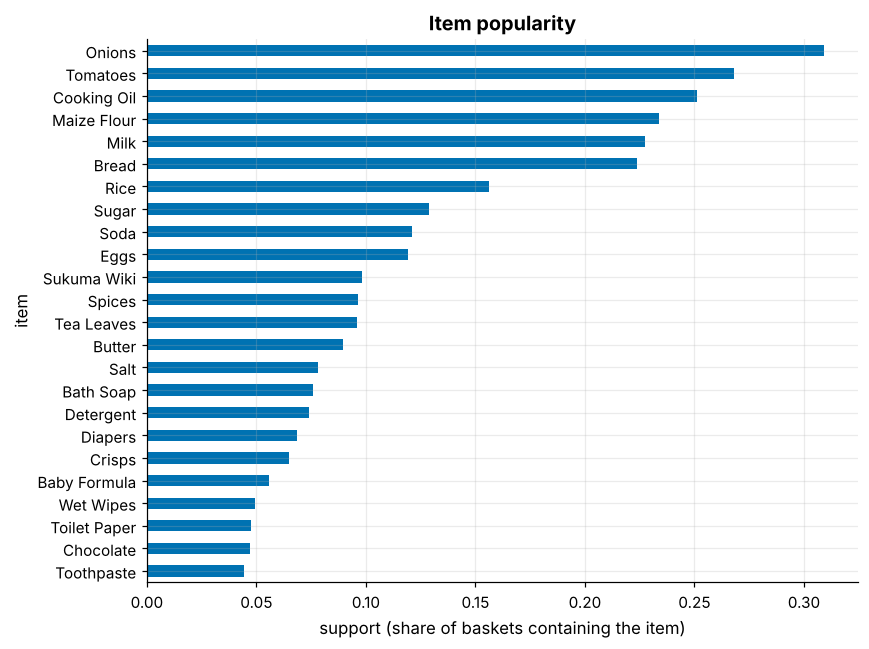

In [6]:
# Which items are most popular? (support of single items)
item_support = groc.groupby("item")["transaction_id"].nunique().sort_values(ascending=False) / baskets.size
fig, ax = plt.subplots(figsize=(8, 6))
item_support.sort_values().plot.barh(ax=ax, color="#0072B2")
ax.set_xlabel("support (share of baskets containing the item)"); ax.set_title("Item popularity")
plt.tight_layout(); plt.show()

### Run our from-scratch Apriori on 2,500 real-ish baskets

In [7]:
freq = apriori_scratch(baskets.tolist(), min_support=0.03)
print(f"\n{len(freq)} frequent itemsets found at min_support = 3%")
largest = max(freq, key=len); print("Largest frequent itemset:", set(largest), f"(support {freq[largest]:.3f})")

level 1:   24 candidates counted ->   24 frequent
level 2:  276 candidates counted ->   40 frequent
level 3:   35 candidates counted ->   24 frequent
level 4:    6 candidates counted ->    2 frequent

90 frequent itemsets found at min_support = 3%
Largest frequent itemset: {'Maize Flour', 'Sugar', 'Onions', 'Cooking Oil'} (support 0.034)


Look at the funnel in the output above: 24 single items give 276 possible pairs, but only **40** pass the support threshold; then only 35 candidate triples need counting (not the 2,024 that exist), and just 6 candidate quadruples. That is the Apriori principle saving us work.

## 6 · Using `mlxtend`: the professional way

`mlxtend` implements Apriori (and the faster **FP-Growth**) plus rule generation. The workflow:

1. **Encode** the baskets into a True/False table: rows = transactions, columns = items.
2. **`apriori`** → frequent itemsets.
3. **`association_rules`** → rules with all the metrics.

In [8]:
import warnings; warnings.filterwarnings("ignore")
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(baskets.tolist()).transform(baskets.tolist()), columns=te.columns_)
onehot.iloc[:5, :8]

,Baby Formula,Bath Soap,Bread,Butter,Chocolate,Cooking Oil,Crisps,Detergent
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,True,False,False
2,False,False,True,True,False,False,False,False
3,False,False,False,False,False,True,False,False
4,False,False,False,False,False,True,False,False


In [9]:
freq_df = apriori(onehot, min_support=0.03, use_colnames=True)
print("mlxtend found", len(freq_df), "frequent itemsets; our scratch version found", len(freq))

# Do the supports agree exactly?
mine = {frozenset(k): v for k, v in freq.items()}
theirs = {frozenset(row.itemsets): row.support for row in freq_df.itertuples()}
print("identical itemsets and supports:", mine.keys() == theirs.keys() and all(abs(mine[k] - theirs[k]) < 1e-9 for k in mine))

mlxtend found 90 frequent itemsets; our scratch version found 90
identical itemsets and supports: True


In [10]:
rules = association_rules(freq_df, metric="confidence", min_threshold=0.5)

def label(fs):                                      # frozenset -> "A, B"
    return ", ".join(sorted(fs))

rules["rule"] = rules["antecedents"].map(label) + "  ⇒  " + rules["consequents"].map(label)
show = ["rule", "support", "confidence", "lift", "leverage"]
print(f"{len(rules)} rules with confidence >= 50%\n")
rules.sort_values("lift", ascending=False)[show].head(12).round(3).reset_index(drop=True)

90 rules with confidence >= 50%



,rule,support,confidence,lift,leverage
0,Diapers ⇒ Wet Wipes,0.040,0.585,11.886,0.037
1,Wet Wipes ⇒ Diapers,0.040,0.813,11.886,0.037
2,Diapers ⇒ Baby Formula,0.044,0.637,11.465,0.040
3,Baby Formula ⇒ Diapers,0.044,0.784,11.465,0.040
4,Toothpaste ⇒ Detergent,0.033,0.748,10.105,0.030
5,Toilet Paper ⇒ Detergent,0.035,0.731,9.880,0.031
6,Detergent ⇒ Bath Soap,0.041,0.557,7.365,0.036
7,Bath Soap ⇒ Detergent,0.041,0.545,7.365,0.036
8,Crisps ⇒ Soda,0.052,0.809,6.694,0.045
9,Chocolate ⇒ Soda,0.035,0.746,6.174,0.029


### Reading the rules like a shop manager 🧠

- **`Wet Wipes ⇒ Diapers`** (lift ≈ 12): customers buying wet wipes buy diapers in ~81% of cases, **12× more often than chance**. The baby-care "shopping mission" is vivid in the data.
- **`Toothpaste ⇒ Detergent`** (lift ≈ 10): household-supplies mission.
- Each pair is listed in **both directions** with the *same lift* (lift is symmetric) but **different confidence**: confidence is the one that depends on direction.

### Visualise all the rules at once
A classic: support vs confidence, with colour = lift.

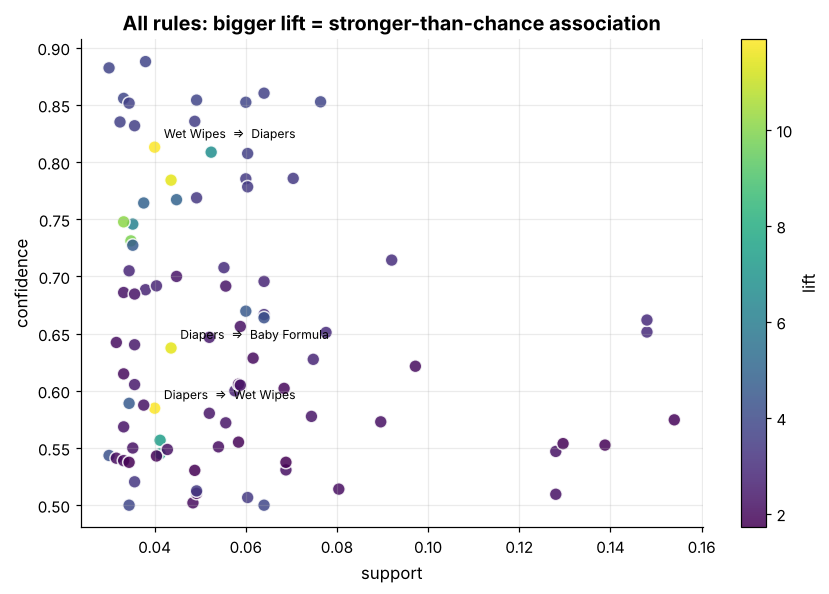

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=70, alpha=.85, edgecolor="white")
plt.colorbar(sc, label="lift")
ax.set_xlabel("support"); ax.set_ylabel("confidence"); ax.set_title("All rules: bigger lift = stronger-than-chance association")
top = rules.sort_values("lift", ascending=False).head(3)
for _, r in top.iterrows():
    ax.annotate(r["rule"], (r["support"], r["confidence"]), fontsize=8, xytext=(6, 6), textcoords="offset points")
plt.tight_layout(); plt.show()

### Choosing thresholds: the art of association mining 🎨

| Parameter | Too low | Too high |
|---|---|---|
| `min_support` | Thousands of rules, mostly noise; slow | You miss rare-but-valuable patterns |
| `min_confidence` | Unreliable rules | Only the obvious ones survive |
| `min_lift` | Coincidences sneak in | Only extreme associations remain |

**A practical recipe:**
1. Start with `min_support` = 1–5% (depends on how many baskets you have; you want each rule backed by *dozens*, not 3, transactions).
2. Keep rules with **lift > 1.2–1.5** and **confidence > 40–60%**.
3. **Remove mirror pairs** if you only need one direction.
4. Rank by lift or leverage; **read the top 20 by eye** and ask: *"Could I act on this?"*

### Multi-item rules
Rules can have several items on each side. Let's look at the 3-item rules:

In [12]:
multi = rules[(rules["antecedents"].map(len) + rules["consequents"].map(len)) >= 3]
print(f"{len(multi)} rules involve 3+ items. Strongest:")
multi.sort_values("lift", ascending=False)[show].head(5).round(3).reset_index(drop=True)

54 rules involve 3+ items. Strongest:


,rule,support,confidence,lift,leverage
0,"Onions, Spices ⇒ Rice",0.045,0.767,4.905,0.036
1,"Spices, Tomatoes ⇒ Rice",0.038,0.764,4.886,0.030
2,"Cooking Oil, Spices ⇒ Rice",0.035,0.727,4.650,0.028
3,"Onions, Sugar ⇒ Cooking Oil, Maize Flour",0.034,0.589,4.602,0.027
4,"Butter ⇒ Bread, Milk",0.060,0.670,4.525,0.047


## 7 · Turning rules into action 🌾

A rule is only useful if it changes a decision. Here's how the numbers map to actions:

| Finding | Action |
|---|---|
| High lift, high confidence, decent support | **Place items near each other**; create a **bundle** |
| High lift, tiny support | Niche: good for **targeted recommendations**, not a store redesign |
| Lift ≈ 1 | **Ignore**: no real association |
| Lift < 1 | Substitutes or *competing* purchases: don't promote together; stock both for variety |

> 🌾 **Agricultural lens.** Association rules are powerful beyond shops:
> - **Cooperatives:** which inputs do members buy together? → design **input packages** and bulk-purchase deals.
> - **Extension services:** which *practices* (improved seed, fertiliser, soil testing) are adopted together? → target training to the "missing" half of a pair.
> - **Crop planning:** which crops are grown together on the same farm? → **intercropping patterns**.
> - **Disease surveillance:** which symptoms co-occur in livestock? → faster diagnosis.

### ⚠️ Pitfalls
1. **Correlation ≠ causation.** "DAP ⇒ seed" doesn't mean discounting DAP will sell seed.
2. **Popular items create trivial rules** (everything "predicts" maize flour). Use **lift**.
3. **Rare items vanish** under a high `min_support`. For rare-but-profitable products, lower the threshold *just for them* or use specialised methods.
4. **Time is ignored.** Apriori treats a basket as an unordered bag. For *sequences* (buy A, *then* B), you need sequential pattern mining.
5. **Redundant rules.** `{A}⇒{B}` and `{A,C}⇒{B}` may say nearly the same thing. Prefer the simpler.
6. **Statistical fluke.** With thousands of candidate rules, some will look good by chance. Insist on support and *replicate on new data*.

## 8 · 🧩 Your turn: practice problems

Exercises 1–3 use the 10-receipt `toy` shop. Exercises 4–5 use the **agro-input** dealer data.

### 🧩 Exercise 1: Metrics by hand
**Difficulty:** ⭐  |  **Time:** ~5 min

Using the `toy` baskets and the helper functions in Section 2, compute for the rule **`{CAN} ⇒ {DAP}`**:

- `s_can`: the support of `{CAN}`
- `s_rule`: the support of the rule (CAN and DAP together)
- `conf_rule`: its confidence
- `lift_rule`: its lift

Is it a *useful* rule? Write one sentence.

<details><summary>💡 Hint 1</summary>

`support({'CAN'})` uses the helper function. `support({'CAN', 'DAP'})` gives the rule's support.

</details>
<details><summary>💡 Hint 2</summary>

confidence = support(CAN ∪ DAP) / support(CAN).

</details>
<details><summary>💡 Hint 3</summary>

lift = confidence / support(DAP).

</details>

In [13]:
s_can = support({"CAN"})
s_rule = support({"CAN", "DAP"})
conf_rule = s_rule / s_can
lift_rule = conf_rule / support({"DAP"})
print(s_can, s_rule, round(conf_rule, 3), round(lift_rule, 3))
# Moderately useful: 75% of CAN baskets also contain DAP, and lift 1.25 says that's somewhat above chance,
# but with only 10 receipts (3 supporting) we wouldn't dare act on it.

0.4 0.3 0.75 1.25


In [14]:
# ✔ Self-check (run me after you've written your answer)
check('support of CAN is 0.4', lambda: abs(s_can - 0.4) < 1e-9)
check('support of the rule is 0.3', lambda: abs(s_rule - 0.3) < 1e-9)
check('confidence is 0.75', lambda: abs(conf_rule - 0.75) < 1e-9)
check('lift is 1.25', lambda: abs(lift_rule - 1.25) < 1e-9)

✅ support of CAN is 0.4


✅ support of the rule is 0.3
✅ confidence is 0.75
✅ lift is 1.25


### 🧩 Exercise 2: Frequent single items
**Difficulty:** ⭐  |  **Time:** ~5 min

Using the `toy` baskets, find `frequent_items`: the **set** of single items whose support is **at least 0.3**.

*(Do it with a `Counter` or the `support` helper; your choice.)*

<details><summary>💡 Hint 1</summary>

`all_items = set().union(*toy)` gives every distinct item.

</details>
<details><summary>💡 Hint 2</summary>

Keep an item if `support({item}) >= 0.3`.

</details>
<details><summary>💡 Hint 3</summary>

Careful with exact boundaries: Pesticide is in exactly 3/10 baskets = 0.3, so use `>=`, not `>`.

</details>

In [15]:
all_items = set().union(*toy)
frequent_items = {i for i in all_items if support({i}) >= 0.3}
print(frequent_items)

{'DAP', 'Seed', 'Pesticide', 'CAN'}


In [16]:
# ✔ Self-check (run me after you've written your answer)
check("frequent_items is {'DAP', 'Seed', 'CAN', 'Pesticide'}", lambda: frequent_items == {'DAP', 'Seed', 'CAN', 'Pesticide'})

✅ frequent_items is {'DAP', 'Seed', 'CAN', 'Pesticide'}


### 🧩 Exercise 3: Candidate generation with pruning
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

This is the heart of Apriori. Write `gen_candidates(freq_k, k)`:

- `freq_k` is a set of frequent **k-itemsets** (each a `frozenset`).
- Return the set of candidate **(k+1)-itemsets**: unions of two frequent k-itemsets that have size k+1 **and whose every k-subset is in `freq_k`** (that's the pruning step).

Test case: 
```python
freq2 = {frozenset(s) for s in [("A","B"), ("A","C"), ("B","C"), ("B","D")]}
```
Only `{A, B, C}` should survive. (`{B, C, D}` is pruned because `{C, D}` isn't frequent; `{A, B, D}` is pruned because `{A, D}` isn't.)

<details><summary>💡 Hint 1</summary>

Loop over `combinations(freq_k, 2)`; compute `union = a | b`.

</details>
<details><summary>💡 Hint 2</summary>

Keep the union only if `len(union) == k + 1`.

</details>
<details><summary>💡 Hint 3</summary>

Pruning test: `all(frozenset(sub) in freq_k for sub in combinations(union, k))`.

</details>

In [17]:
freq2 = {frozenset(s) for s in [("A", "B"), ("A", "C"), ("B", "C"), ("B", "D")]}

def gen_candidates(freq_k, k):
    out = set()
    for a, b in combinations(freq_k, 2):
        union = a | b
        if len(union) == k + 1 and all(frozenset(sub) in freq_k for sub in combinations(union, k)):
            out.add(union)
    return out

print(gen_candidates(freq2, 2))

{frozenset({'C', 'A', 'B'})}


In [18]:
# ✔ Self-check (run me after you've written your answer)
check('only {A, B, C} survives', lambda: gen_candidates(freq2, 2) == {frozenset({'A', 'B', 'C'})})
check('works for k=1 (all pairs of singletons)', lambda: len(gen_candidates({frozenset([x]) for x in 'ABCD'}, 1)) == 6)

✅ only {A, B, C} survives
✅ works for k=1 (all pairs of singletons)


**Now the agro-input dealer data.** Prepare it once, then use it for Exercises 4 and 5:

In [19]:
agro = load("agro_input_baskets")
agro_baskets = agro.groupby("transaction_id")["item"].apply(list).tolist()
te_a = TransactionEncoder()
onehot_agro = pd.DataFrame(te_a.fit(agro_baskets).transform(agro_baskets), columns=te_a.columns_)
print(f"{len(agro_baskets):,} receipts, {onehot_agro.shape[1]} products")

3,000 receipts, 22 products


### 🧩 Exercise 4: Mine the agro-dealer's receipts
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

On `onehot_agro`:

1. `freq_agro = apriori(onehot_agro, min_support=0.03, use_colnames=True)`
2. Build `rules_agro` with `association_rules(..., metric="confidence", min_threshold=0.5)`, then **keep only rules with `lift >= 1.5`**.
3. `n_rules` = how many rules remain.
4. `top_rule` = the row with the **highest lift**; set `top_antecedent` and `top_consequent` to its **sets of item names** (convert the frozensets with `set(...)`).

<details><summary>💡 Hint 1</summary>

`rules_agro = rules_agro[rules_agro['lift'] >= 1.5]`.

</details>
<details><summary>💡 Hint 2</summary>

`top_rule = rules_agro.sort_values('lift', ascending=False).iloc[0]`.

</details>
<details><summary>💡 Hint 3</summary>

`top_antecedent = set(top_rule['antecedents'])`. Remember each row's antecedents is a `frozenset`.

</details>

In [20]:
freq_agro = apriori(onehot_agro, min_support=0.03, use_colnames=True)
rules_agro = association_rules(freq_agro, metric="confidence", min_threshold=0.5)
rules_agro = rules_agro[rules_agro["lift"] >= 1.5]
n_rules = len(rules_agro)
top_rule = rules_agro.sort_values("lift", ascending=False).iloc[0]
top_antecedent, top_consequent = set(top_rule["antecedents"]), set(top_rule["consequents"])
print(n_rules, top_antecedent, "=>", top_consequent, round(top_rule["lift"], 2))

43 {'Drinkers & Feeders'} => {'Poultry Feed'} 9.39


In [21]:
# ✔ Self-check (run me after you've written your answer)
check('43 rules survive the filters', lambda: n_rules == 43)
check('the strongest rule is Drinkers & Feeders => Poultry Feed', lambda: top_antecedent == {'Drinkers & Feeders'} and top_consequent == {'Poultry Feed'})
check('its lift is above 9', lambda: top_rule['lift'] > 9)

✅ 43 rules survive the filters
✅ the strongest rule is Drinkers & Feeders => Poultry Feed
✅ its lift is above 9


### 🧩 Exercise 5: The negative association: lift below 1
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Not every pattern is "bought together". Some products are **competitors or substitutes**: farmers tend to buy one *or* the other.

Using `freq_agro` from Exercise 4, build `all_rules = association_rules(freq_agro, metric="lift", min_threshold=0)` (this keeps rules of **every** lift) and find the rule with the **lowest lift**:

- `lowest_lift`: its lift value
- `low_items`: the **set** of the items involved (antecedent ∪ consequent)

Then explain *in a comment* what lift < 1 means for the dealer's marketing.

<details><summary>💡 Hint 1</summary>

`min_threshold=0` on the lift metric means *keep everything with lift ≥ 0*, i.e. all of them.

</details>
<details><summary>💡 Hint 2</summary>

`row = all_rules.sort_values('lift').iloc[0]`

</details>
<details><summary>💡 Hint 3</summary>

`low_items = set(row['antecedents']) | set(row['consequents'])`

</details>

In [22]:
all_rules = association_rules(freq_agro, metric="lift", min_threshold=0)
row = all_rules.sort_values("lift").iloc[0]
lowest_lift = row["lift"]
low_items = set(row["antecedents"]) | set(row["consequents"])
print(round(lowest_lift, 2), low_items)
# Lift 0.6: Pesticide and DAP appear together only 60% as often as chance predicts. They serve different 'missions'
# (crop protection vs. planting). Do NOT bundle them; promote each to its own audience.

0.6 {'DAP Fertilizer', 'Pesticide'}


In [23]:
# ✔ Self-check (run me after you've written your answer)
check('lowest lift is below 1', lambda: lowest_lift < 1)
check('the pair is Pesticide and DAP Fertilizer', lambda: low_items == {'Pesticide', 'DAP Fertilizer'})

✅ lowest lift is below 1
✅ the pair is Pesticide and DAP Fertilizer


### 🧩 Exercise 6: 🏆 Challenge: generate the rules yourself
**Difficulty:** ⭐⭐⭐  |  **Time:** ~20 min

`mlxtend`'s `association_rules` is phase two of Apriori. Write it yourself.

`rules_from_itemsets(freq, min_conf)` takes the dict returned by `apriori_scratch` (`{frozenset: support}`) and returns a **list of tuples** `(antecedent, consequent, support, confidence, lift)` for **every** rule `A ⇒ B` where:
- `A ∪ B` is a frequent itemset with at least 2 items, `A` and `B` are non-empty and disjoint,
- `confidence = support(A ∪ B) / support(A) >= min_conf`.

*(Because of the Apriori principle, every subset of a frequent itemset is also in `freq`, so you can look up supports directly.)*

**Test:** on the agro baskets with `min_support=0.03` and `min_conf=0.5`, you should get exactly the same number of rules as `mlxtend` gives at that confidence threshold.

<details><summary>💡 Hint 1</summary>

For each itemset with ≥ 2 items, loop over antecedent sizes `r` from 1 to `len(itemset) - 1` with `combinations(itemset, r)`.

</details>
<details><summary>💡 Hint 2</summary>

`A = frozenset(a)`; `B = itemset - A`; `conf = freq[itemset] / freq[A]`; `lift = conf / freq[B]`.

</details>
<details><summary>💡 Hint 3</summary>

Append `(A, B, freq[itemset], conf, lift)` when `conf >= min_conf`.

</details>

In [24]:
freq_agro_scratch = apriori_scratch(agro_baskets, min_support=0.03, verbose=False)

def rules_from_itemsets(freq, min_conf):
    out = []
    for itemset, s in freq.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for a in combinations(itemset, r):
                A = frozenset(a); B = itemset - A
                conf = s / freq[A]
                if conf >= min_conf:
                    out.append((A, B, s, conf, conf / freq[B]))
    return out

mine_rules = rules_from_itemsets(freq_agro_scratch, 0.5)
print(len(mine_rules), "rules (mlxtend gives", len(association_rules(freq_agro, metric="confidence", min_threshold=0.5)), ")")

43 rules (mlxtend gives 43 )


In [25]:
# ✔ Self-check (run me after you've written your answer)
check('same number of rules as mlxtend at confidence >= 0.5', lambda: len(rules_from_itemsets(freq_agro_scratch, 0.5)) == len(association_rules(freq_agro, metric='confidence', min_threshold=0.5)))
check('the strongest-lift rule has lift above 9', lambda: max(r[4] for r in rules_from_itemsets(freq_agro_scratch, 0.5)) > 9)

✅ same number of rules as mlxtend at confidence >= 0.5
✅ the strongest-lift rule has lift above 9


### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** In one sentence each, what do support, confidence, and lift tell you about a rule A ⇒ B?

<details><summary>Show answer</summary>

**Support**: how common the combination is (share of all baskets containing A and B). **Confidence**: of baskets with A, the share that also contain B (P(B|A)). **Lift**: how many times more often A and B co-occur than if they were independent.

</details>

**Q2.** A rule has support 0.45, confidence 0.90, and lift 1.0. Is it interesting?

<details><summary>Show answer</summary>

No. Lift = 1 means A and B are independent: B is simply so popular (support 0.90) that it appears with everything. High confidence is misleading here.

</details>

**Q3.** Rule {A}⇒{B} has confidence 0.8 and {B}⇒{A} has confidence 0.2. Can their lifts differ?

<details><summary>Show answer</summary>

No. **Lift is symmetric** (P(A∩B) / (P(A)·P(B))) so both directions have the *same* lift. Only confidence is directional.

</details>

**Q4.** State the Apriori principle and explain how it speeds up the algorithm.

<details><summary>Show answer</summary>

Every subset of a frequent itemset is frequent; equivalently, any superset of an infrequent itemset is infrequent. So once we know an item (or itemset) is infrequent we never need to count any itemset containing it: huge parts of the search space are pruned.

</details>

**Q5.** A rule shows lift 0.6. What should the shopkeeper do?

<details><summary>Show answer</summary>

It signals a **negative association**: the items co-occur less than chance (substitutes, or serving different needs). Don't bundle or co-promote them; consider promoting each separately to its own audience.

</details>

**Q6.** You lower min_support from 5% to 0.1% and get 40,000 rules. Is that progress?

<details><summary>Show answer</summary>

Usually not. Most are noise or rare flukes backed by only a handful of baskets. Raise thresholds, filter by lift/leverage, and review the top rules manually: you want *few, actionable, reliable* rules.

</details>

## 9 · Summary & cheat sheet 📝

| Concept | Remember |
|---|---|
| **Support** | share of baskets containing the itemset |
| **Confidence** | $P(B\mid A)$: directional |
| **Lift** | $P(A\cap B)/[P(A)P(B)]$; 1 = independent, >1 positive, <1 negative; symmetric |
| **Apriori principle** | subsets of frequent sets are frequent → prune candidates |
| **Two phases** | (1) frequent itemsets (2) rules from itemsets |
| **Practical filter** | support ≥ 1–5%, lift ≥ 1.2–1.5, confidence ≥ 40–60%; read the top rules |
| **Beware** | correlation ≠ causation; popular items; rare items; no time order |

```python
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(list_of_baskets).transform(list_of_baskets), columns=te.columns_)
freq  = apriori(onehot, min_support=0.03, use_colnames=True)          # or fpgrowth(...) for speed
rules = association_rules(freq, metric="lift", min_threshold=1.2)
rules.sort_values("lift", ascending=False)
```

### 🚀 Stretch ideas
- Try `fpgrowth` instead of `apriori`: same results, how much faster on 100k baskets?
- Filter rules by **leverage** or **conviction**. Which ranking finds the most "actionable" rules?
- Look up **sequential pattern mining** (PrefixSpan) for "A *then* B".

### 📚 Next up
**Lesson 6: Evaluating & Profiling Clusters:** with no answer key, how do we judge a clustering, and tell its story to a decision-maker? 📊